# Проверка SVD данных без обучения сети

POD строится **только на train**; для A,n берём одну строку на среду. Методы задаются в METHODS: по умолчанию full в корневой версии и randomized в отдельной директории. Для совместного сравнения выберите оба метода; mass-lumped метрика едина. Validation-кривые реконструкции считаем в consistent комплексной FEM L2 норме. Test здесь не используется.

Для $W=\operatorname{diag}(M\mathbf1)$ разлагаем $(X-\bar X)W^{1/2}=U\Sigma V^T$, сохраняем $\Phi=W^{-1/2}V_r$. Тогда $\Phi^TW\Phi=I$. Энергия делится на энергию **всей** центрированной матрицы, включая хвост за вычисленным рангом. Знаки отдельных SVD-векторов не сравниваем: используем principal angles.

**Статичная задача:** геометрия и исходная среда №0 фиксированы; A,n и DG0-материалы одинаковы во всех примерах. Меняются k и θ. Один medium_id=0, разбиение по frequency_id: 670/170/160 частот (5360/1360/1280 полей). 1000 частот × 8 направлений = 8000 полей на полосу. Этот эксперимент проверяет интерполяцию параметров волны на одной среде.

**Профиль:** выберите `POD_METHOD="full"` или `"randomized"` в первой ячейке. Данные общие; пути результатов разделены. Сохранённые outputs относятся к randomized. Это выбор алгоритма POD, а не отдельные версии Chebyshev/FNO.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'neural_operator').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from neural_operator import settings as full_settings
from neural_operator.randomized import settings as randomized_settings
POD_METHOD = "randomized"  # "full" uses separate runs; saved outputs below are randomized.
if POD_METHOD not in {"full", "randomized"}:
    raise ValueError("POD_METHOD must be full or randomized")
settings = randomized_settings if POD_METHOD == "randomized" else full_settings
BASE, N_FREQUENCIES, N_DIRECTIONS, DATASET_TAG = (settings.BASE, settings.N_FREQUENCIES,
    settings.N_DIRECTIONS, settings.DATASET_TAG)
LOW_DATA_DIR, HIGH_DATA_DIR = settings.LOW_DATA_DIR, settings.HIGH_DATA_DIR
LOW_RUNS, HIGH_RUNS = settings.LOW_RUNS, settings.HIGH_RUNS
SVD_RUNS, COMPARISON_RUNS = settings.SVD_RUNS, settings.COMPARISON_RUNS
DATA_DIR = LOW_DATA_DIR
RUNS = LOW_RUNS
import json
import numpy as np
import matplotlib.pyplot as plt
from neural_operator.datasets import load_dataset, write_dataset_info
from neural_operator.plotting import display_table, plot_prediction, plot_history


In [2]:
from neural_operator.diagnostics import svd_diagnostics, transfer_diagnostics, write_csv
from neural_operator.plotting import plot_svd
dataset = load_dataset(DATA_DIR, mmap=True)
OUT = SVD_RUNS
MAX_RANK = 96
METHODS = [POD_METHOD]  # Use ['full', 'randomized'] for an explicit joint comparison.
summary, curves, spectra = svd_diagnostics(dataset, OUT, max_rank=MAX_RANK, seed=42, methods=METHODS)
display_table(summary)


field,method,snapshots,algorithm_used,computed_rank,seconds,orthogonality_fro,retained_centered_energy,snapshot_array_bytes,mode_array_bytes
A,randomized,1,constant,0,0.00016533,0,0,25768,0
n,randomized,1,constant,0,7.6166e-05,0,0,25768,0
real,randomized,5360,randomized,88,2.1825,2.2307e-14,1,138116480,2267584
imag,randomized,5360,randomized,86,1.8115,2.1854e-14,1,138116480,2216048


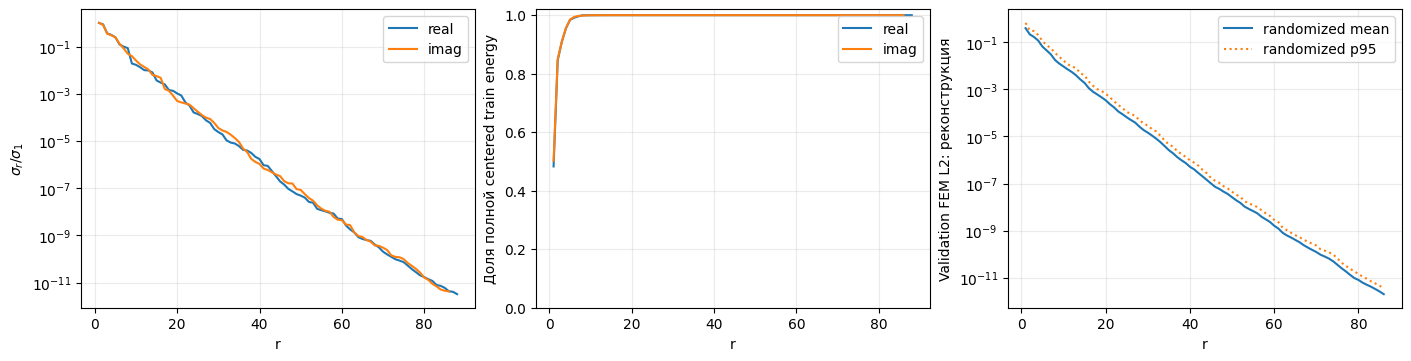

method,rank,mean,p95,target_attained
randomized,10,0.0095057,0.017142,True


In [3]:
figure = plot_svd(curves, spectra)
figure.savefig(OUT / 'svd_diagnostics.png', dpi=160)
plt.show()
threshold = .01
recommendations = []
for method in METHODS:
    rows = [r for r in curves if r['method'] == method]
    adequate = [r for r in rows if r['mean_fem_l2'] <= threshold]
    best = adequate[0] if adequate else rows[-1]
    recommendations.append({'method': method, 'rank': best['rank'], 'mean': best['mean_fem_l2'],
                            'p95': best['p95_fem_l2'], 'target_attained': bool(adequate)})
display_table(recommendations)


## Ошибка FEM → grid → FEM

Для FNO используем равномерную сетку, для Chebyshev — узлы Lobatto. Перенос использует исходные FEM-треугольники. Таблица показывает ошибку одной интерполяции; это не ошибка нейросети и не строгая нижняя граница достижимой ошибки. Память в SVD-таблице — размер хранимых массивов, а не peak RAM BLAS.


In [4]:
transfer_rows = transfer_diagnostics(dataset, resolution=32)
display_table(transfer_rows)
write_csv(OUT / 'transfer_validation.csv', transfer_rows)


grid,resolution,field,mean_fem_l2,p95_fem_l2
uniform,32,A,0.0066646,0.0066646
uniform,32,n,0.032489,0.032489
uniform,32,u_scat,0.026247,0.028336
chebyshev,32,A,0.01,0.01
chebyshev,32,n,0.047662,0.047662
chebyshev,32,u_scat,0.041246,0.045591


Training по умолчанию ограничивает POD ранг 48 для небольшого локального эксперимента и явно сообщает, если цель 1% на validation недостижима. Чтобы проверить другой ранг, измените TrainConfig и каталог запуска; test не используйте для подбора. Mass-lumped проекция не является оптимальной consistent FEM-проекцией на этот span. Обоснование и источники: [docs/methods.md](../docs/methods.md), [docs/references.md](../docs/references.md).
